In [1]:
# 1. Imports, fixed settings, and file paths (no models fitted here)
import io, json, os, platform, warnings, time, hashlib, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import matplotlib.pyplot as plt
import scipy, sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, confusion_matrix, brier_score_loss)
from sklearn.inspection import permutation_importance
from IPython.display import display

SEED = 42
RESULTS = Path('/content/cis631_independent_results')
RESULTS.mkdir(parents=True, exist_ok=True)
CACHE = Path('/content/cis631_nhanes_cache')
CACHE.mkdir(parents=True, exist_ok=True)

CYCLES = {
    '2007-2008': ('2007', '_E', 'CRP'),
    '2009-2010': ('2009', '_F', 'CRP'),
    '2015-2016': ('2015', '_I', 'HSCRP'),
    '2017-2020': ('2017', '_P', 'HSCRP'),
}
DEV_CYCLES = ['2009-2010', '2015-2016', '2017-2020']
TEST_CYCLE = '2007-2008'
CBC_FIELDS = ['LBXWBCSI','LBXRBCSI','LBXHGB','LBXHCT','LBXMCVSI',
              'LBXMCHSI','LBXMC','LBXRDW','LBXPLTSI']
DIETARY = ['avg_iron','avg_vitamin_c','avg_calories','avg_protein',
           'avg_fiber','avg_calcium','avg_caffeine','avg_alcohol']
LIFESTYLE_NUM = ['PAD680','DSDCOUNT']
LIFESTYLE_CAT = ['PAQ650','PAQ665','smoking_status','DSD010']
REPRODUCTIVE_NUM = ['num_pregnancies','num_live_birth_deliveries','years_since_last_birth']
REPRODUCTIVE_CAT = ['RHQ031','RHD280','breastfeeding_status']
DEMOGRAPHIC_NUM = ['RIDAGEYR','INDFMPIR','BMXBMI']
DEMOGRAPHIC_CAT = ['RIDRETH1','DMDEDUC2']
NUMERIC = DEMOGRAPHIC_NUM + DIETARY + LIFESTYLE_NUM + REPRODUCTIVE_NUM
CATEGORICAL = DEMOGRAPHIC_CAT + LIFESTYLE_CAT + REPRODUCTIVE_CAT
ALL_FEATURES = NUMERIC + CATEGORICAL
assert len(ALL_FEATURES) == len(set(ALL_FEATURES)) == 25
print('Predeclared',len(ALL_FEATURES),'compatible non-lab features. The 2007–2008 test results will not be used for model selection.')

Predeclared 25 compatible non-lab features. The 2007–2008 test results will not be used for model selection.


## 2. Download and harmonize four NHANES periods

This section downloads only public NHANES XPT files (no USDA FPED download). It checks that *every* preselected input variable exists in each release and **stops rather than silently removing predictors** if a variable cannot be retrieved. Predictor compatibility and the ferritin assay bridge were specified before evaluation. Data downloads are cached during this Colab session.

In [2]:
session = requests.Session()
retry = Retry(total=3, backoff_factor=1, status_forcelist=[429,500,502,503,504])
session.mount('https://', HTTPAdapter(max_retries=retry))

def nhanes_xpt(cycle, stem):
    year, suffix, _ = CYCLES[cycle]
    prefix = 'P_' if suffix == '_P' else ''
    filebase = prefix + stem if suffix == '_P' else stem + suffix
    url = f'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{year}/DataFiles/{filebase}.XPT'
    target = CACHE / (cycle + '_' + filebase + '.xpt')
    if not target.exists():
        r = session.get(url, timeout=90)
        r.raise_for_status()
        if len(r.content) < 300 or r.content[:25].lower().startswith(b'<!doctype'):
            raise RuntimeError(f'Expected XPT file but received another response: {url}')
        target.write_bytes(r.content)
    try:
        return pd.read_sas(target, format='xport')
    except Exception as exc:
        raise RuntimeError(f'Could not parse XPT from {url}: {exc}') from exc

def require_columns(frame, columns, origin):
    absent = sorted(set(columns) - set(frame.columns))
    if absent:
        raise ValueError(f'{origin} is missing {absent}. STOP: investigate documented compatibility before changing the predeclared analysis.')
    return frame[['SEQN'] + [c for c in columns if c != 'SEQN']].copy()

def clean_code(series, invalid):
    return pd.to_numeric(series, errors='coerce').replace(list(invalid), np.nan)

def merge_one(left, right):
    return left.merge(right, on='SEQN', how='left', validate='one_to_one')

def load_cycle(cycle):
    _, _, crp_stem = CYCLES[cycle]
    needed = ['DEMO','FERTIN','CBC',crp_stem,'DR1TOT','DR2TOT','RHQ','PAQ','SMQ','DSQTOT','BMX']
    raw = {}
    for name in needed:
        raw[name] = nhanes_xpt(cycle, name)
    demo = raw['DEMO']
    democols = ['RIAGENDR','RIDAGEYR','RIDEXPRG','RIDRETH1','DMDEDUC2','INDFMPIR']
    frame = require_columns(demo, democols, cycle+' DEMO')
    # Filter demographic eligibility before attaching other files, but DO NOT look at outcomes.
    frame = frame.loc[(frame.RIAGENDR == 2) & frame.RIDAGEYR.between(20,44)
                      & (frame.RIDEXPRG == 2)].copy()
    frame = merge_one(frame, require_columns(raw['FERTIN'], ['LBXFER'],cycle+' FERTIN'))
    frame = merge_one(frame, require_columns(raw['CBC'], CBC_FIELDS, cycle+' CBC'))
    crp_col = 'LBXHSCRP' if crp_stem == 'HSCRP' else 'LBXCRP'
    frame = merge_one(frame, require_columns(raw[crp_stem], [crp_col],cycle+' CRP'))
    frame['CRP_mgL'] = pd.to_numeric(frame[crp_col],errors='coerce') * (1 if crp_stem == 'HSCRP' else 10)
    frame = merge_one(frame, require_columns(raw['BMX'], ['BMXBMI'],cycle+' BMI'))
    dnames = ['IRON','VC','KCAL','PROT','FIBE','CALC','CAFF','ALCO']
    for day in [1,2]:
        cols = ['DR'+str(day)+'T'+name for name in dnames]
        frame = merge_one(frame, require_columns(raw['DR'+str(day)+'TOT'],cols,cycle+' dietary day '+str(day)))
    rhqcols = ['RHQ031','RHQ131','RHQ160','RHQ171','RHD190','RHQ200','RHD280']
    frame = merge_one(frame,require_columns(raw['RHQ'],rhqcols,cycle+' reproductive'))
    frame = merge_one(frame,require_columns(raw['PAQ'],['PAQ650','PAQ665','PAD680'],cycle+' physical activity'))
    frame = merge_one(frame,require_columns(raw['SMQ'],['SMQ020','SMQ040','SMD650'],cycle+' smoking'))
    frame = merge_one(frame,require_columns(raw['DSQTOT'],['DSD010','DSDCOUNT'],cycle+' supplements'))
    frame['cycle'] = cycle

    # Blood-based cohort definition only. 2007 assay converted to 2009 assay scale using CDC's bridge.
    frame['ferritin_raw'] = pd.to_numeric(frame.LBXFER,errors='coerce')
    frame['ferritin_comparable'] = frame.ferritin_raw
    if cycle == '2007-2008':
        valid = frame.ferritin_raw > 0
        frame.loc[valid,'ferritin_comparable'] = 10 ** (0.989 * np.log10(frame.loc[valid,'ferritin_raw']) + 0.049)
    frame['smoking_status'] = np.select(
        [(frame.SMQ020 == 2),
         ((frame.SMQ020 == 1) & frame.SMQ040.isin([1,2])),
         ((frame.SMQ020 == 1) & (frame.SMQ040 == 3))],
        ['never','current','former'],default='Missing')
    cigarettes = clean_code(frame['SMD650'],[777,999])
    adjustment = np.zeros(len(frame))
    current = frame.smoking_status.eq('current').to_numpy()
    adjustment[current] = 0.3
    adjustment[current & cigarettes.between(10,19).to_numpy()] = 0.5
    adjustment[current & cigarettes.ge(20).to_numpy()] = 0.6
    frame['hemoglobin_adjusted'] = pd.to_numeric(frame.LBXHGB,errors='coerce') - adjustment
    frame = frame.loc[frame.CRP_mgL.notna() & frame.CRP_mgL.le(5)
                     & frame.hemoglobin_adjusted.ge(12)
                     & frame.ferritin_comparable.notna()].copy()
    frame['iron_deficient'] = (frame.ferritin_comparable < 15).astype(int)
    frame['iron_deficient_30'] = (frame.ferritin_comparable < 30).astype(int)

    # Same recall averaging and reproducible code cleaning as the earlier project.
    for new,short in [('avg_iron','IRON'),('avg_vitamin_c','VC'),('avg_calories','KCAL'),
                      ('avg_protein','PROT'),('avg_fiber','FIBE'),('avg_calcium','CALC'),
                      ('avg_caffeine','CAFF'),('avg_alcohol','ALCO')]:
        pair = [f'DR1T{short}',f'DR2T{short}']
        frame[new] = frame[pair].apply(pd.to_numeric,errors='coerce').mean(axis=1)
    frame['PAD680'] = clean_code(frame['PAD680'],[7777,9999])
    frame.loc[~frame['PAD680'].between(0,1440),'PAD680'] = np.nan
    frame['DSDCOUNT'] = clean_code(frame['DSDCOUNT'],[77,99,777,999])
    frame['RHQ160'] = clean_code(frame['RHQ160'],[77,99,777,999])
    frame['RHQ171'] = clean_code(frame['RHQ171'],[77,99,777,999])
    # SAS transport zero may appear as a tiny positive float; treat that as 0 for delivery counts.
    frame.loc[frame.RHQ171.between(0,1e-8),'RHQ171'] = 0
    frame['RHD190'] = clean_code(frame['RHD190'],[77,99,777,999])
    frame['num_pregnancies'] = frame['RHQ160'].where(frame.RHQ160.between(0,30))
    frame['num_live_birth_deliveries'] = frame['RHQ171'].where(frame.RHQ171.between(0,30))
    # Never-pregnant women have 0 pregnancies/deliveries by design.
    frame.loc[frame.RHQ131.eq(2),['num_pregnancies','num_live_birth_deliveries']] = 0
    frame['years_since_last_birth'] = (frame.RIDAGEYR-frame.RHD190).where(
        frame.num_live_birth_deliveries.gt(0))
    frame.loc[~frame.years_since_last_birth.between(0,45),'years_since_last_birth']=np.nan
    frame['breastfeeding_status'] = frame.RHQ200.map({1:'yes',2:'no'}).fillna('not_asked')
    for c in ['RIDRETH1','DMDEDUC2','PAQ650','PAQ665','DSD010','RHQ031','RHD280']:
        frame[c] = clean_code(frame[c],[7,9,77,99,777,999])
    for c in NUMERIC:
        frame[c] = pd.to_numeric(frame[c],errors='coerce')
    for c in CATEGORICAL:
        frame[c] = frame[c].astype('string').fillna('Missing').astype(str)
    assert frame['SEQN'].is_unique, f'Duplicate participant IDs in {cycle}'
    return frame[['SEQN','cycle','iron_deficient','iron_deficient_30','ferritin_raw',
                  'ferritin_comparable','CRP_mgL','hemoglobin_adjusted'] + ALL_FEATURES + CBC_FIELDS].copy()

# No performance metrics are calculated here. Model choices remain frozen in the next cell.
# Loading four cycles downloads public files; it is normal for this step to take several minutes.
cohorts = {cycle:load_cycle(cycle) for cycle in CYCLES}
for cycle in CYCLES:
    print(f'{cycle}: eligible participants = {len(cohorts[cycle])}')
combined = pd.concat(cohorts.values(),ignore_index=True)
assert not combined.duplicated(['cycle','SEQN']).any()
assert not set(combined[combined.cycle==TEST_CYCLE].SEQN).intersection(
    combined[combined.cycle.isin(DEV_CYCLES)].SEQN)
assert not set(ALL_FEATURES).intersection(CBC_FIELDS+['ferritin_comparable','CRP_mgL'])
# Check non-lab variable availability in DEVELOPMENT ONLY. Missing values are imputed inside CV folds.
assert all(combined.loc[combined.cycle.isin(DEV_CYCLES),c].notna().any() for c in NUMERIC), 'One development predictor is entirely missing.'
combined.to_csv(RESULTS/'eligible_cohort_with_features.csv',index=False)
print('Prepared the eligible data; next step freezes development-only decisions before opening 2007–2008 results.')

2007-2008: eligible participants = 669
2009-2010: eligible participants = 793
2015-2016: eligible participants = 662
2017-2020: eligible participants = 942
Prepared the eligible data; next step freezes development-only decisions before opening 2007–2008 results.


In [3]:
DEV = combined[combined.cycle.isin(DEV_CYCLES)].reset_index(drop=True)
TEST = combined[combined.cycle.eq(TEST_CYCLE)].reset_index(drop=True)
assert DEV.iron_deficient.sum() >= 20 and TEST.iron_deficient.sum() >= 5
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)

def prep(features,scaled=False):
    nums = [x for x in features if x in NUMERIC or x in CBC_FIELDS]
    cats = [x for x in features if x in CATEGORICAL]
    tx = []
    if nums:
        stages = [('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True))]
        if scaled: stages.append(('scale',StandardScaler()))
        tx.append(('num',Pipeline(stages),nums))
    if cats:
        tx.append(('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cats))
    return ColumnTransformer(tx,remainder='drop',sparse_threshold=0)

def model_family(name):
    if name == 'LogisticRegression': return LogisticRegression(max_iter=3000,class_weight='balanced',C=1.0,random_state=SEED)
    if name == 'RandomForest': return RandomForestClassifier(n_estimators=170,min_samples_leaf=10,class_weight='balanced_subsample',random_state=SEED,n_jobs=-1)
    if name == 'HistogramGradientBoosting': return HistGradientBoostingClassifier(max_iter=120,max_leaf_nodes=15,l2_regularization=1.0,early_stopping=False,random_state=SEED)
    if name == 'DecisionTree': return DecisionTreeClassifier(max_depth=5,min_samples_leaf=20,class_weight='balanced',random_state=SEED)
    if name == 'KNN': return KNeighborsClassifier(n_neighbors=25,weights='distance')
    if name == 'SVM_RBF': return SVC(C=1.0,kernel='rbf',gamma='scale',class_weight='balanced',probability=True,random_state=SEED)
    raise KeyError(name)

FAMILIES=['LogisticRegression','RandomForest','HistogramGradientBoosting','DecisionTree','KNN','SVM_RBF']

def pipeline(name,features):
    return Pipeline([('prep',prep(features,scaled=name in {'LogisticRegression','KNN','SVM_RBF'})),
                     ('clf',model_family(name))])

def decision_threshold(y,probs,target_recall=0.80):
    positive = np.asarray(probs)[np.asarray(y)==1]
    if not len(positive): raise ValueError('No development positives to choose threshold')
    # The 20th percentile of development positive scores aims for >=80% sensitivity.
    return float(np.quantile(positive,1-target_recall))

def metrics(y,probs,threshold,cycle,model,split):
    y = np.asarray(y,int)
    p = np.asarray(probs,float)
    flag = p>=threshold
    tn,fp,fn,tp = confusion_matrix(y,flag,labels=[0,1]).ravel()
    return dict(cycle=cycle,model=model,split=split,n=len(y),positives=int(y.sum()),
                prevalence=float(y.mean()),AUROC=float(roc_auc_score(y,p)) if len(np.unique(y))==2 else np.nan,
                AP=float(average_precision_score(y,p)) if y.sum() else np.nan,
                recall=float(recall_score(y,flag,zero_division=0)),
                precision=float(precision_score(y,flag,zero_division=0)),
                Brier=float(brier_score_loss(y,p)),threshold=float(threshold),
                TP=int(tp),FP=int(fp),TN=int(tn),FN=int(fn))

# Development predictions; the TEST labels are NEVER used in these fits or decisions.
cv_scores = {}
selected_thresholds = {}
cv_rows=[]
for name in FAMILIES + ['CBC_HistogramBoosting']:
    feats = CBC_FIELDS if name.startswith('CBC_') else ALL_FEATURES
    family = 'HistogramGradientBoosting' if name.startswith('CBC_') else name
    estimator = pipeline(family,feats)
    print('Development-only 5-fold CV:',name,flush=True)
    oof = cross_val_predict(estimator,DEV[feats],DEV.iron_deficient.to_numpy(),cv=cv,
                            method='predict_proba',n_jobs=1)[:,1]
    threshold=decision_threshold(DEV.iron_deficient,oof)
    cv_scores[name]=oof
    selected_thresholds[name]=threshold
    cv_rows.append(metrics(DEV.iron_deficient,oof,threshold,'pooled development',name,'OOF'))
cv_table = pd.DataFrame(cv_rows).sort_values('AP',ascending=False)
cv_table.to_csv(RESULTS/'development_oof_model_comparison.csv',index=False)
main = cv_table[~cv_table.model.str.startswith('CBC_')].iloc[0]['model']
print('DEVELOPMENT-SELECTED non-lab model:', main)
display(cv_table[['model','AUROC','AP','recall','precision','threshold']])
# Freeze all selections before reading any 2007–2008 model evaluation results.
frozen = dict(seed=SEED,development_cycles=DEV_CYCLES,test_cycle=TEST_CYCLE,
              nonlab_predictors=ALL_FEATURES,cbc_predictors=CBC_FIELDS,
              selected_nonlab_model=main,thresholds=selected_thresholds,
              selection_metric='5-fold development out-of-fold average precision',
              ferritin_2007_bridge='10**(0.989*log10(2007_ferritin)+0.049)',
              target_recall_development=0.80,models=FAMILIES)
(RESULTS/'pretest_frozen_specification.json').write_text(json.dumps(frozen,indent=2))

Development-only 5-fold CV: LogisticRegression
Development-only 5-fold CV: RandomForest
Development-only 5-fold CV: HistogramGradientBoosting
Development-only 5-fold CV: DecisionTree
Development-only 5-fold CV: KNN
Development-only 5-fold CV: SVM_RBF
Development-only 5-fold CV: CBC_HistogramBoosting
DEVELOPMENT-SELECTED non-lab model: LogisticRegression


,model,AUROC,AP,recall,precision,threshold
6,CBC_HistogramBoosting,0.762288,0.359746,0.797710,0.178632,0.030167
0,LogisticRegression,0.573538,0.149524,0.797710,0.116956,0.380363
5,SVM_RBF,0.565450,0.149303,0.797710,0.115470,0.092889
1,RandomForest,0.596280,0.142796,0.797710,0.131281,0.273270
2,HistogramGradientBoosting,0.569423,0.141467,0.797710,0.119771,0.029773
4,KNN,0.560580,0.140830,0.797710,0.114021,0.073455
3,DecisionTree,0.578768,0.139523,0.812977,0.124561,0.418064


1474

In [4]:
heldout_rows=[]
all_predictions = TEST[['SEQN','cycle','iron_deficient','iron_deficient_30']].copy()
fitted_models={}
for name in FAMILIES + ['CBC_HistogramBoosting']:
    feats = CBC_FIELDS if name.startswith('CBC_') else ALL_FEATURES
    family = 'HistogramGradientBoosting' if name.startswith('CBC_') else name
    fitted = pipeline(family,feats).fit(DEV[feats],DEV.iron_deficient)
    fitted_models[name]=fitted
    prob = fitted.predict_proba(TEST[feats])[:,1]
    all_predictions[name+'_prob']=prob
    heldout_rows.append(metrics(TEST.iron_deficient,prob,selected_thresholds[name],TEST_CYCLE,name,'independent'))
    print('Evaluated:',name,flush=True)
heldout_table=pd.DataFrame(heldout_rows)
heldout_table.to_csv(RESULTS/'independent_2007_model_comparison.csv',index=False)
all_predictions.to_csv(RESULTS/'independent_2007_participant_predictions.csv',index=False)
print('Independent 2007–2008 evaluation; main model selected ONLY by development AP:',main)
display(heldout_table[['model','n','positives','AUROC','AP','recall','precision','TP','FP','FN']].sort_values('AP',ascending=False))

# Per-cycle performance for development cycles is out-of-fold, NOT in-sample.
cycle_metrics=[]
for name in FAMILIES + ['CBC_HistogramBoosting']:
    for cycle in DEV_CYCLES:
        mask=DEV.cycle.eq(cycle)
        cycle_metrics.append(metrics(DEV.loc[mask,'iron_deficient'],cv_scores[name][mask.to_numpy()],
                                     selected_thresholds[name],cycle,name,'development OOF'))
    cycle_metrics.append(heldout_table.loc[heldout_table.model==name].iloc[0].to_dict())
cycle_table=pd.DataFrame(cycle_metrics)
cycle_table.to_csv(RESULTS/'performance_by_nhanes_cycle.csv',index=False)
print('Cycle-specific metrics (development is OOF; 2007 is independent):')
display(cycle_table[cycle_table.model==main][['cycle','split','n','positives','AUROC','AP','recall','precision']])

Evaluated: LogisticRegression
Evaluated: RandomForest
Evaluated: HistogramGradientBoosting
Evaluated: DecisionTree
Evaluated: KNN
Evaluated: SVM_RBF
Evaluated: CBC_HistogramBoosting
Independent 2007–2008 evaluation; main model selected ONLY by development AP: LogisticRegression


,model,n,positives,AUROC,AP,recall,precision,TP,FP,FN
6,CBC_HistogramBoosting,669,75,0.749091,0.347510,0.760000,0.171171,57,276,18
5,SVM_RBF,669,75,0.565006,0.161990,0.773333,0.117886,58,434,17
1,RandomForest,669,75,0.575892,0.141060,0.786667,0.124211,59,416,16
0,LogisticRegression,669,75,0.540314,0.138060,0.840000,0.116022,63,480,12
2,HistogramGradientBoosting,669,75,0.546869,0.135247,0.880000,0.123827,66,467,9
3,DecisionTree,669,75,0.555713,0.126819,0.813333,0.121032,61,443,14
4,KNN,669,75,0.512907,0.120858,0.800000,0.112570,60,473,15


Cycle-specific metrics (development is OOF; 2007 is independent):


,cycle,split,n,positives,AUROC,AP,recall,precision
0,2009-2010,development OOF,793,97,0.579986,0.156947,0.876289,0.139344
1,2015-2016,development OOF,662,73,0.528386,0.162076,0.712329,0.104628
2,2017-2020,development OOF,942,92,0.594578,0.142923,0.782609,0.105882
3,2007-2008,independent,669,75,0.540314,0.138060,0.840000,0.116022


## 5. Nested predictor-group ablation (required RQ3 comparison)

The groups below follow the requested exact progression: **dietary only → dietary+lifestyle → dietary+lifestyle+reproductive**. Demographic predictors are not silently added to a “diet-only” arm. We additionally report the full 25-variable model separately. The same prespecified logistic regression settings and training protocol are used throughout.

In [5]:
AB_GROUPS = {
  'dietary_only': DIETARY,
  'dietary_lifestyle': DIETARY+LIFESTYLE_NUM+LIFESTYLE_CAT,
  'dietary_lifestyle_reproductive': DIETARY+LIFESTYLE_NUM+LIFESTYLE_CAT+REPRODUCTIVE_NUM+REPRODUCTIVE_CAT,
  'all_25_including_demographics': ALL_FEATURES,
}
ablation_rows=[]
for label,feat in AB_GROUPS.items():
    classifier=pipeline('LogisticRegression',feat)
    oof=cross_val_predict(classifier,DEV[feat],DEV.iron_deficient,cv=cv,method='predict_proba',n_jobs=1)[:,1]
    threshold=decision_threshold(DEV.iron_deficient,oof)
    ablation_rows.append(dict(feature_group=label,feature_count=len(feat),**metrics(DEV.iron_deficient,oof,threshold,
                                                                                     'pooled development','LogisticRegression','OOF')))
    # One-time independent evaluation for a PREDEFINED analysis; no selection based on it.
    fit=classifier.fit(DEV[feat],DEV.iron_deficient)
    p=fit.predict_proba(TEST[feat])[:,1]
    ablation_rows.append(dict(feature_group=label,feature_count=len(feat),**metrics(TEST.iron_deficient,p,threshold,
                                                                                     TEST_CYCLE,'LogisticRegression','independent')))
ablation=pd.DataFrame(ablation_rows)
ablation.to_csv(RESULTS/'nested_feature_group_ablation.csv',index=False)
display(ablation[['feature_group','feature_count','split','AUROC','AP','recall','precision']])

,feature_group,feature_count,split,AUROC,AP,recall,precision
0,dietary_only,8,OOF,0.503696,0.106470,0.797710,0.115342
1,dietary_only,8,independent,0.534680,0.121233,0.853333,0.117864
2,dietary_lifestyle,14,OOF,0.504847,0.107812,0.797710,0.109942
3,dietary_lifestyle,14,independent,0.524736,0.128326,0.880000,0.112628
4,dietary_lifestyle_reproductive,20,OOF,0.584569,0.146201,0.797710,0.122294
5,dietary_lifestyle_reproductive,20,independent,0.572817,0.157729,0.866667,0.122873
6,all_25_including_demographics,25,OOF,0.573538,0.149524,0.797710,0.116956
7,all_25_including_demographics,25,independent,0.540314,0.138060,0.840000,0.116022


Independent test importance — interpretation ONLY:


,predictor,mean_AP_drop,SD_permutation,fraction_positive_drop
14,num_live_birth_deliveries,0.019686,0.008755,1.000000
15,years_since_last_birth,0.008770,0.008660,0.733333
6,avg_protein,0.007134,0.004472,0.933333
23,RHD280,0.002943,0.012703,0.666667
2,BMXBMI,0.001480,0.002156,0.800000
5,avg_calories,0.001432,0.001305,0.866667
22,RHQ031,0.001129,0.009934,0.533333
10,avg_alcohol,0.001021,0.002440,0.600000
7,avg_fiber,0.000990,0.003683,0.666667
19,PAQ665,0.000949,0.002515,0.666667


,predictor,mean,std,min,max
8,RHD280,0.035079,0.035691,-0.005051,0.074513
21,num_live_birth_deliveries,0.032718,0.029878,-0.012909,0.067986
9,RHQ031,0.030390,0.017981,0.008635,0.056600
24,years_since_last_birth,0.025791,0.018134,-0.003831,0.045003
20,breastfeeding_status,0.014522,0.012281,-0.000434,0.030485
18,avg_protein,0.010671,0.012354,0.000195,0.031635
22,num_pregnancies,0.010484,0.013327,0.001038,0.032727
11,RIDRETH1,0.009406,0.025885,-0.014324,0.052673
14,avg_calcium,0.008124,0.018450,-0.003731,0.040597
2,DSD010,0.006745,0.007853,-0.001200,0.018009


Largest absolute logistic coefficients (positive means higher modeled log odds conditional on other features):


,encoded_term,coefficient,sign,abs_coefficient
56,cat__RHD280_Missing,1.458867,positive,1.458867
54,cat__RHD280_1.0,-1.202081,negative,1.202081
51,cat__RHQ031_1.0,0.935849,positive,0.935849
52,cat__RHQ031_2.0,-0.918994,negative,0.918994
45,cat__smoking_status_Missing,0.561427,positive,0.561427
35,cat__DMDEDUC2_1.0,-0.392302,negative,0.392302
26,num__missingindicator_PAD680,-0.377022,negative,0.377022
57,cat__breastfeeding_status_no,0.344030,positive,0.344030
30,cat__RIDRETH1_1.0,0.340525,positive,0.340525
14,num__num_live_birth_deliveries,0.315838,positive,0.315838


Independent evaluation gap: {'CBC_minus_development_selected_nonlab_AUROC': 0.20877665544332213, 'CI95_low': 0.09456891659121025, 'CI95_high': 0.30953113925742026, 'bootstrap_valid_samples': 1000}


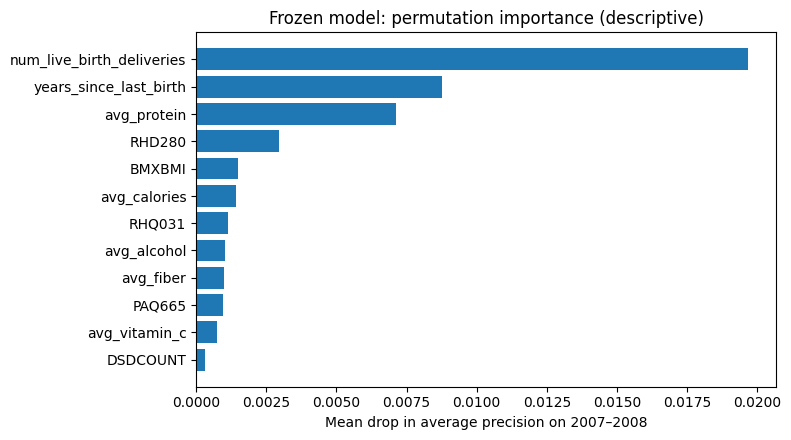

In [6]:
# Feature importance of the model chosen before the 2007 evaluation.
winner = fitted_models[main]
Xtest=TEST[ALL_FEATURES]
ytest=TEST.iron_deficient.to_numpy()
importance=permutation_importance(winner,Xtest,ytest,scoring='average_precision',
                                  n_repeats=15,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'predictor':ALL_FEATURES,
                               'mean_AP_drop':importance.importances_mean,
                               'SD_permutation':importance.importances_std,
                               'fraction_positive_drop':(importance.importances>0).mean(axis=1)})
importance_table.sort_values('mean_AP_drop',ascending=False,inplace=True)
importance_table.to_csv(RESULTS/'independent_test_permutation_importance.csv',index=False)
print('Independent test importance — interpretation ONLY:')
display(importance_table.head(12))

# Stability from 5 development validation folds, 3 permutations each (no independent data used).
fold_importances=[]
for fold,(tr,va) in enumerate(cv.split(DEV[ALL_FEATURES],DEV.iron_deficient)):
    model=pipeline(main,ALL_FEATURES).fit(DEV.iloc[tr][ALL_FEATURES],DEV.iloc[tr].iron_deficient)
    perm=permutation_importance(model,DEV.iloc[va][ALL_FEATURES],DEV.iloc[va].iron_deficient,
                                scoring='average_precision',n_repeats=3,random_state=SEED+fold,n_jobs=1)
    fold_importances.extend({'fold':fold,'predictor':f,'AP_drop':float(v)}
                           for f,v in zip(ALL_FEATURES,perm.importances_mean))
fold_table=pd.DataFrame(fold_importances)
fold_table.to_csv(RESULTS/'development_permutation_by_fold.csv',index=False)
fold_stability=fold_table.groupby('predictor').AP_drop.agg(['mean','std','min','max']).reset_index().sort_values('mean',ascending=False)
fold_stability.to_csv(RESULTS/'development_importance_stability.csv',index=False)
display(fold_stability.head(12))

# Coefficient direction of the final logistic model. Coefficients are CONDITIONAL associations, not causal effects.
lr=fitted_models['LogisticRegression']
coef_labels=lr.named_steps['prep'].get_feature_names_out()
coef_table=pd.DataFrame({'encoded_term':coef_labels,
                         'coefficient':lr.named_steps['clf'].coef_.ravel()})
coef_table['sign']=np.where(coef_table.coefficient>0,'positive',
                            np.where(coef_table.coefficient<0,'negative','zero'))
coef_table['abs_coefficient']=coef_table.coefficient.abs()
coef_table.sort_values('abs_coefficient',ascending=False).to_csv(RESULTS/'logistic_coefficient_direction.csv',index=False)
print('Largest absolute logistic coefficients (positive means higher modeled log odds conditional on other features):')
display(coef_table.sort_values('abs_coefficient',ascending=False).head(15))

# Paired bootstrap difference: CBC minus the DEVELOPMENT-SELECTED non-lab model.
rng=np.random.default_rng(SEED)
pa=all_predictions[main+'_prob'].to_numpy()
pb=all_predictions['CBC_HistogramBoosting_prob'].to_numpy()
diffs=[]
for _ in range(1000):
    ids=rng.integers(0,len(ytest),len(ytest))
    if len(np.unique(ytest[ids]))<2:continue
    diffs.append(roc_auc_score(ytest[ids],pb[ids])-roc_auc_score(ytest[ids],pa[ids]))
if not diffs:raise RuntimeError('Could not bootstrap both classes')
gap={'CBC_minus_development_selected_nonlab_AUROC':float(roc_auc_score(ytest,pb)-roc_auc_score(ytest,pa)),
     'CI95_low':float(np.quantile(diffs,.025)),'CI95_high':float(np.quantile(diffs,.975)),
     'bootstrap_valid_samples':len(diffs)}
(RESULTS/'independent_CBC_vs_nonlab_gap.json').write_text(json.dumps(gap,indent=2))
print('Independent evaluation gap:',gap)

plt.figure(figsize=(8,4.5))
plot=importance_table.head(12).iloc[::-1]
plt.barh(plot.predictor,plot.mean_AP_drop)
plt.xlabel('Mean drop in average precision on 2007–2008')
plt.title('Frozen model: permutation importance (descriptive)')
plt.tight_layout()
plt.savefig(RESULTS/'independent_permutation_importance.png',dpi=160)
plt.show()

In [7]:
# Sensitivity: ferritin below 30 µg/L, using prespecified LR and CBC models only.
sensitivity_rows=[]
for name,features in [('LogisticRegression',ALL_FEATURES),('CBC_HistogramBoosting',CBC_FIELDS)]:
    family='HistogramGradientBoosting' if name.startswith('CBC_') else name
    mod=pipeline(family,features)
    oof=cross_val_predict(mod,DEV[features],DEV.iron_deficient_30,cv=cv,method='predict_proba',n_jobs=1)[:,1]
    th=decision_threshold(DEV.iron_deficient_30,oof)
    sensitivity_rows.append(metrics(DEV.iron_deficient_30,oof,th,'pooled development',name,'OOF'))
    fitted=mod.fit(DEV[features],DEV.iron_deficient_30)
    p=fitted.predict_proba(TEST[features])[:,1]
    sensitivity_rows.append(metrics(TEST.iron_deficient_30,p,th,TEST_CYCLE,name,'independent'))
sens=pd.DataFrame(sensitivity_rows)
sens.to_csv(RESULTS/'sensitivity_30_comparison.csv',index=False)
display(sens[['model','split','n','positives','AUROC','AP','recall','precision']])

# Source names and feature derivations; do not mislabel FPED proxies as iron intake.
source_map={
  'RIDAGEYR':'DEMO: RIDAGEYR (age)', 'INDFMPIR':'DEMO: INDFMPIR (family income / poverty ratio)',
  'BMXBMI':'BMX: BMXBMI (BMI)', 'RIDRETH1':'DEMO: RIDRETH1 (race/ethnicity)',
  'DMDEDUC2':'DEMO: DMDEDUC2 (education)',
  'PAQ650':'PAQ: PAQ650 (vigorous leisure activity)', 'PAQ665':'PAQ: PAQ665 (moderate leisure activity)',
  'PAD680':'PAQ: PAD680 (sedentary minutes)', 'smoking_status':'SMQ: SMQ020 + SMQ040',
  'DSDCOUNT':'DSQTOT: DSDCOUNT (number of dietary supplements)',
  'DSD010':'DSQTOT: DSD010 (supplement use)',
  'num_pregnancies':'RHQ: RHQ160 + RHQ131 (never-pregnant code)',
  'num_live_birth_deliveries':'RHQ: RHQ171 + RHQ131 (never-pregnant code)',
  'years_since_last_birth':'DEMO RIDAGEYR minus RHQ RHD190, only where live-birth deliveries >0',
  'RHQ031':'RHQ: RHQ031 (regular periods past 12 months)',
  'RHD280':'RHQ: RHD280 (hysterectomy)',
  'breastfeeding_status':'RHQ: RHQ200 (breastfeeding yes/no/skip)',
}
for name,code in [('avg_iron','IRON'),('avg_vitamin_c','VC'),('avg_calories','KCAL'),
                  ('avg_protein','PROT'),('avg_fiber','FIBE'),('avg_calcium','CALC'),
                  ('avg_caffeine','CAFF'),('avg_alcohol','ALCO')]:
    source_map[name]=f'DR1TOT DR1T{code} and DR2TOT DR2T{code}; available-day mean'
feature_dictionary=pd.DataFrame([{'predictor':f,'type':('numeric' if f in NUMERIC else 'categorical'),
                                  'source_and_derivation':source_map[f]} for f in ALL_FEATURES])
feature_dictionary.to_csv(RESULTS/'final_predictor_dictionary.csv',index=False)
cohort_summary=combined.groupby('cycle').agg(n=('SEQN','size'),primary_cases=('iron_deficient','sum'),
                                             sensitivity_cases=('iron_deficient_30','sum')).reset_index()
cohort_summary.to_csv(RESULTS/'cohort_by_cycle.csv',index=False)
display(cohort_summary)

manifest={**frozen,'generated_python':platform.python_version(),
          'numpy':np.__version__,'pandas':pd.__version__,
          'scikit_learn':sklearn.__version__,'scipy':scipy.__version__,
          'clinical_label_ferritin_ug_L':{'primary_lt':15,'sensitivity_lt':30},
          'minimum_adjusted_hemoglobin_g_dL':12,'CRP_max_mg_L':5,
          'test_used_for_model_selection':False,
          'development_CV':'StratifiedKFold(5,shuffle=True,random_state=42)',
          'no_survey_weighted_ML_claim':True,
          'test_is_earlier_cycle_not_future_forecast':True,
          'cannot_prove_prospective_pre_blood_draw_screening':True,
          'sources':{'CDC_2007':'https://wwwn.cdc.gov/nchs/nhanes/search/DataPage.aspx?Cycle=2007-2008',
                     'CDC_ferritin_bridge':'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/FERTIN_F.htm'},
          'raw_cache_files':[p.name for p in CACHE.glob('*.xpt')]}
(RESULTS/'reproducibility_manifest.json').write_text(json.dumps(manifest,indent=2))
(RESULTS/'validation_notes.txt').write_text(
  'This is a new backward-in-time, out-of-cycle evaluation on previously unused NHANES 2007–2008.\n'
  'Older 2017–2020 evaluation was exploratory and not a fully independent test.\n'
  'Two original FPED-derived proxy features were removed to retain compatible predictors (25 total).\n'
  'Ferritin 2007–2008 was bridged using the CDC 2009–2010 analytic note.\n'
  'CV performance is OOF within development; 2007–2008 performance is independent of model selection.\n'
  'No NHANES sampling-weighted ML metrics or deployment claims are made.\n')
# Participant-level rows and trained models may be large; bundle ONLY summary files in public GitHub.
from shutil import make_archive
zipfile_path=make_archive('/content/cis631_independent_results','zip',root_dir=RESULTS)
print('Results ZIP:',zipfile_path)
print('Saved files:', sorted(x.name for x in RESULTS.iterdir()))
print('Primary conclusion must be based on 2007–2008 results above; old 2017 AUROCs are historical only.')

,model,split,n,positives,AUROC,AP,recall,precision
0,LogisticRegression,OOF,2397,804,0.592594,0.405141,0.799751,0.366591
1,LogisticRegression,independent,669,247,0.597252,0.427791,0.894737,0.415414
2,CBC_HistogramBoosting,OOF,2397,804,0.652517,0.502747,0.799751,0.382738
3,CBC_HistogramBoosting,independent,669,247,0.644838,0.546521,0.757085,0.424036


,cycle,n,primary_cases,sensitivity_cases
0,2007-2008,669,75,247
1,2009-2010,793,97,274
2,2015-2016,662,73,220
3,2017-2020,942,92,310


Results ZIP: /content/cis631_independent_results.zip
Saved files: ['cohort_by_cycle.csv', 'development_importance_stability.csv', 'development_oof_model_comparison.csv', 'development_permutation_by_fold.csv', 'eligible_cohort_with_features.csv', 'final_predictor_dictionary.csv', 'independent_2007_model_comparison.csv', 'independent_2007_participant_predictions.csv', 'independent_CBC_vs_nonlab_gap.json', 'independent_permutation_importance.png', 'independent_test_permutation_importance.csv', 'logistic_coefficient_direction.csv', 'nested_feature_group_ablation.csv', 'performance_by_nhanes_cycle.csv', 'pretest_frozen_specification.json', 'reproducibility_manifest.json', 'sensitivity_30_comparison.csv', 'validation_notes.txt']
Primary conclusion must be based on 2007–2008 results above; old 2017 AUROCs are historical only.


In [9]:
from google.colab import files
files.download('/content/cis631_independent_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>